# Modelagem - Segmentação por Clustering
Neste estágio do projeto, iniciamos a exploração de padrões não supervisionados. Após a limpeza e preparação realizadas na fase de EDA, utilizaremos o algoritmo **K-Means** para identificar nichos de mercado baseados no desempenho comercial regional.

**Objetivo desta etapa:**
1. Determinar o número ideal de agrupamentos ($k$) através do Método do Cotovelo.
2. Treinar o modelo baseline.
3. Caracterizar quantitativamente os perfis de vendas de cada cluster.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configuração de estilo
sns.set_theme(style="whitegrid")

# Carregando os dados preparados na fase de EDA
df = pd.read_csv('vgsales_cleaned.csv')

print(f"Dataset carregado com sucesso: {df.shape[0]} registros e {df.shape[1]} colunas.")

Dataset carregado com sucesso: 16291 registros e 17 colunas.


## 1. Seleção de Atributos e Normalização
Para o agrupamento, utilizaremos as variáveis de vendas regionais transformadas em logaritmo: `NA_Sales_log`, `EU_Sales_log`, `JP_Sales_log` e `Other_Sales_log`. 

**Justificativa Técnica:**
*   **Exclusão de Global_Sales:** Não incluímos a venda global no cálculo da distância para evitar redundância, visto que ela é a soma das demais regiões.
*   **Padronização (StandardScaler):** O K-Means utiliza a distância euclidiana. Como as escalas de vendas variam entre regiões (ex: NA vende muito mais que o Japão em volume absoluto), a padronização garante que todas as regiões tenham o mesmo peso matemático no modelo (média 0 e desvio padrão 1).

In [9]:
# Seleção das features
features = ['NA_Sales_log', 'EU_Sales_log', 'JP_Sales_log', 'Other_Sales_log']
X = df[features]

# Aplicando a padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 2. Definindo o Número de Clusters (Método do Cotovelo)
O Método do Cotovelo (*Elbow Method*) analisa a Inércia (soma dos quadrados das distâncias internas). O objetivo é encontrar o ponto onde a adição de um novo cluster não traz um ganho significativo na coesão do grupo — visualmente, onde a curva "dobra".

c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


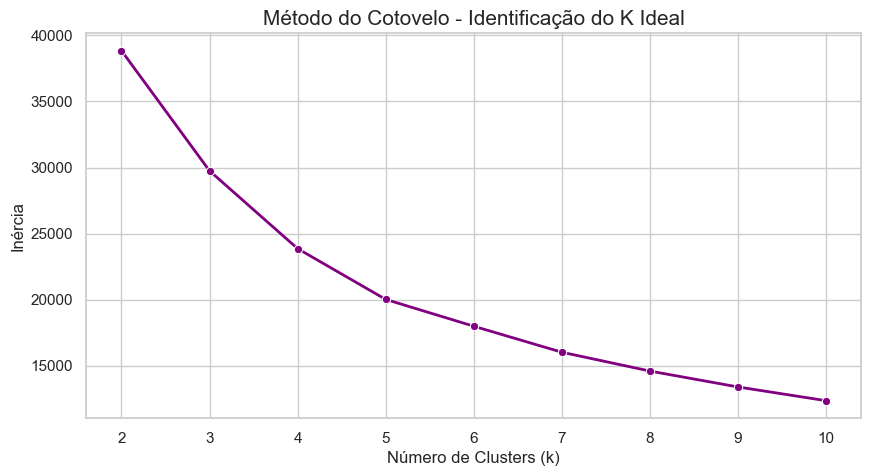

In [10]:
inercia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)


plt.figure(figsize=(10, 5))
sns.lineplot(x=K_range, y=inercia, marker='o', color='purple', linewidth=2)
plt.title('Método do Cotovelo - Identificação do K Ideal', fontsize=15)
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(K_range)
plt.show()

### Análise do Gráfico do Cotovelo
*(Nota para o grupo: Ao observar o gráfico acima, o "cotovelo" geralmente se forma entre k=3, k=4 ou k=5. Para este experimento inicial, seguiremos com **k=4**, que permite uma separação equilibrada entre sucessos globais, nichos regionais e jogos de baixo desempenho.)*

In [11]:
# Executando o modelo final com o K escolhido
K_ideal = 4
kmeans_final = KMeans(n_clusters=K_ideal, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"Algoritmo K-Means executado com k={K_ideal}.")

Algoritmo K-Means executado com k=4.


## 3. Perfil Quantitativo dos Clusters
Nesta etapa, analisamos as médias de vendas (nas unidades originais, em milhões) para entender o comportamento comercial de cada grupo gerado pelo algoritmo.

In [12]:
# Colunas de vendas originais para análise
vendas_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

# Calculando a média de vendas por cluster
analise_clusters = df.groupby('Cluster')[vendas_cols].mean().sort_values(by='Global_Sales', ascending=False)

print("Vendas Médias por Cluster (em milhões de cópias):")
display(analise_clusters)

# Contagem de jogos por cluster
print("\nDistribuição de jogos por cluster:")
display(df['Cluster'].value_counts().sort_index())

Vendas Médias por Cluster (em milhões de cópias):


,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Cluster,,,,,
3,4.011107,2.777273,1.079249,0.963715,8.830791
2,0.890936,0.525301,0.045851,0.165219,1.627357
1,0.317089,0.131327,0.816486,0.039864,1.304947
0,0.101991,0.044323,0.028348,0.014692,0.189679



Distribuição de jogos por cluster:


Cluster
0    13430
1      663
2     1945
3      253
Name: count, dtype: int64

## 4. Interpretação dos Resultados (Insights de Negócio)

A execução do K-Means com $k=4$ revelou uma segmentação clara e estratégica da indústria de videogames, baseada no comportamento regional de consumo:

1. **Cluster 3 - "Hits Globais" (253 jogos):** É o grupo de elite. Jogos que performam excepcionalmente bem em todas as regiões, com média de 8.8 milhões de vendas globais. São os "System Sellers" (ex: Mario, GTA, Call of Duty).
2. **Cluster 2 - "Sucessos Ocidentais" (1.945 jogos):** Jogos com forte penetração nos mercados da América do Norte (0.89M) e Europa (0.52M), mas com baixíssima tração no Japão (0.04M). Reflete gêneros como Esportes e FPS ocidentais.
3. **Cluster 1 - "Especialistas Japoneses" (663 jogos):** Um dos achados mais interessantes. Este grupo vende muito bem no Japão (média de 0.81M), superando inclusive suas vendas na América do Norte (0.31M). É o nicho de JRPGs e jogos culturais específicos que o projeto visa investigar.
4. **Cluster 0 - "The Long Tail" (13.430 jogos):** A grande massa da indústria. Jogos com baixo impacto comercial (média de 0.18M), representando a vasta maioria dos lançamentos que não atingem o status de hit em nenhuma região.

**Próximos Passos:** Cruzar estes 4 perfis com as variáveis de Gênero e Editora para verificar quais empresas dominam cada nicho.